# 02 — The battery objective and equivalent coordinates

One candidate is $\theta=(R_0,R_1,\tau_1,R_2,\tau_2)$, with $\tau_j=R_jC_j$. With discharge-positive current, $\widehat V=U(\mathrm{SOC})-IR_0-v_1-v_2$ and $\dot v_j=-v_j/\tau_j+R_j I/\tau_j$. RC states start at zero after the long preparatory rest.

We use the exact constant-input transition on each measured interval. The primary loss is mean squared voltage residual on DST-80%; FUDS is only assessed after a recommendation. This simple isothermal, constant-parameter model is deliberately limited.

Flow: dimensionless candidate → positive physical parameters → simulated voltage → measured-voltage residual → scalar MSE.

In [1]:
from pathlib import Path
import os, json, sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/bo_vs_es").exists())
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / "artifacts/.matplotlib"))
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from bo_vs_es.analysis.study import save_figure
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 15)
print("Repository:", ROOT)
print("Python:", sys.version.split()[0])


Repository: /Users/mihirsinha/Downloads/repo/Dsa4212-final-project-bayesian-vs-evolutionary
Python: 3.13.6


/Users/mihirsinha/Downloads/repo/Dsa4212-final-project-bayesian-vs-evolutionary/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
from bo_vs_es.objectives.models import Battery, physical, dimensionless, Domain, rotation, LOWER, UPPER, PARAMETERS
from bo_vs_es.analysis.study import reference_fit, curvature
battery = Battery()
u = np.zeros(5)
theta = physical(u)
display(pd.DataFrame({"parameter":PARAMETERS,"lower":LOWER,"example":theta,"upper":UPPER}))
print("Example candidate u:", u)
print("Calibration MSE (V²):", battery(u))
print("Prediction output shape:", battery.prediction(theta).shape)

,parameter,lower,example,upper
0,R0_ohm,0.0010,0.014142,0.2
1,R1_ohm,0.0001,0.004472,0.2
2,tau1_s,1.0000,44.721360,2000.0
3,R2_ohm,0.0001,0.004472,0.2
4,tau2_s,1.0000,44.721360,2000.0


Example candidate u: [0. 0. 0. 0. 0.]
Calibration MSE (V²): 0.006486600187248905
Prediction output shape: (3578,)


## A structure-exploiting reference
Bounded nonlinear least squares receives the residual vector, whereas BO and CMA receive only scalar loss. This is a useful practical reference, not an identical-information competitor. Three starts share a maximum of 300 actual simulator calls; numerical-difference calls are included. The search stops when the counted allocation is reached.

Reference fits use the **full physical box**. Their values must not be treated as achievable lower bounds for the smaller ball domain. A one-RC fit tests whether the second branch is useful; we keep the declared two-RC study even if its advantage is small, and report that limitation.

In [3]:
reference_one = reference_fit(branches=1)
reference_two = reference_fit(branches=2)
reference_uncorrected = reference_fit(branches=2, corrected=False)
references = [reference_one, reference_two, reference_uncorrected]
display(pd.DataFrame([{k:r[k] for k in ["branches","corrected","evaluations","search_s","calibration_rmse_v","fuds80_rmse_v","fuds50_rmse_v"]} for r in references]))
display(pd.DataFrame({"parameter":PARAMETERS,"two_RC_reference":reference_two["theta"]}))
print("Reference u norm (ball feasible only if <=1):", np.linalg.norm(reference_two["u"]))
print("Source reference artifacts: artifacts/references/{1rc_corrected,2rc_corrected,2rc_uncorrected}.json")
print("Reference terminations:",reference_two["terminations"])
original=np.array(reference_two["theta"])
swapped=original[[0,3,4,1,2]]
print("Swapping RC branch labels changes voltage by (V):",np.max(np.abs(battery.prediction(original)-battery.prediction(swapped))))
print("Reference time-constant separation:",max(original[2],original[4])/min(original[2],original[4]))
pd.DataFrame(references).to_csv(ROOT/"results/tables/reference_fits.csv",index=False)

,branches,corrected,evaluations,search_s,calibration_rmse_v,fuds80_rmse_v,fuds50_rmse_v
0,1,True,300,0.234637,0.006246,0.007996,0.006997
1,2,True,300,0.435332,0.003973,0.004745,0.003207
2,2,False,300,0.435948,0.004497,0.005214,0.003420


,parameter,two_RC_reference
0,R0_ohm,0.073494
1,R1_ohm,0.014575
2,tau1_s,18.722935
3,R2_ohm,0.042665
4,tau2_s,481.545735


Reference u norm (ball feasible only if <=1): 1.1311063537306263
Source reference artifacts: artifacts/references/{1rc_corrected,2rc_corrected,2rc_uncorrected}.json
Reference terminations: ['Counted simulator-call allocation reached', 'Counted simulator-call allocation reached', 'Counted simulator-call allocation reached']
Swapping RC branch labels changes voltage by (V): 4.440892098500626e-16
Reference time-constant separation: 25.719564410887354


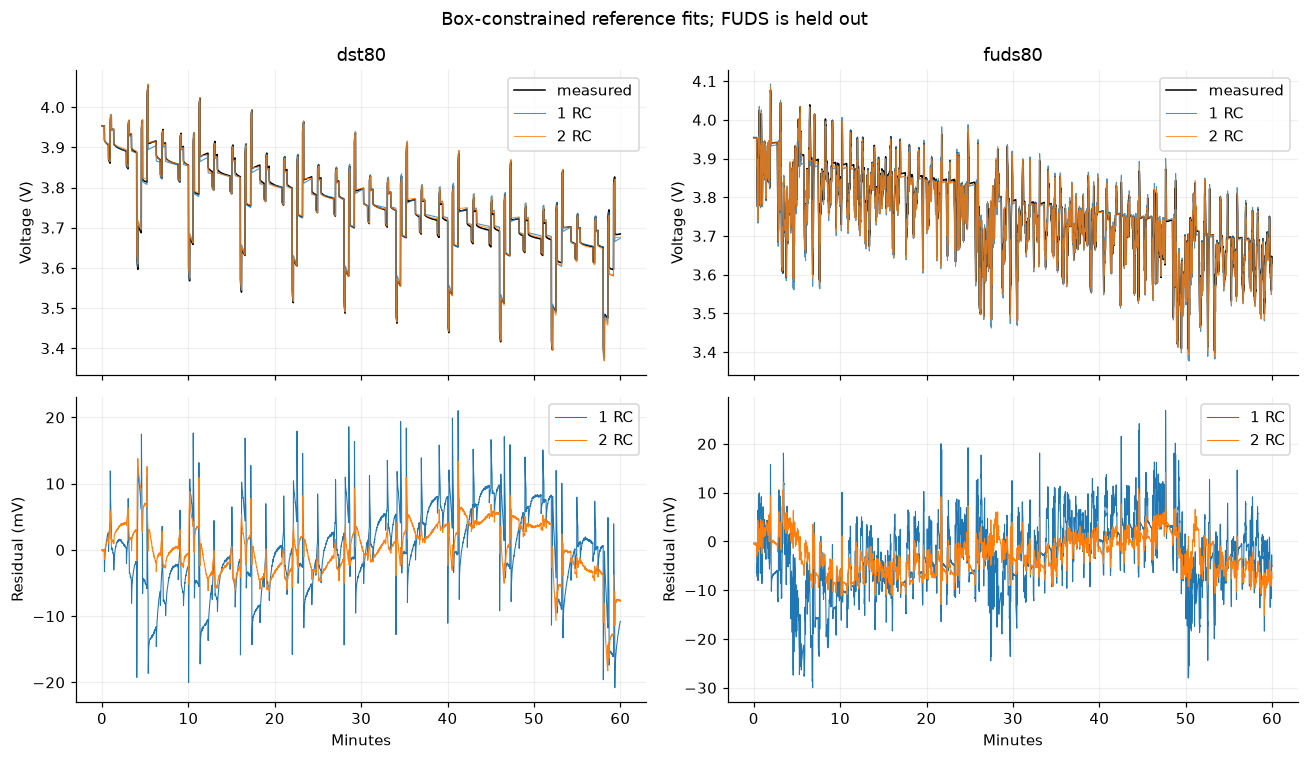

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12,7), sharex="col")
for column,label in enumerate(["dst80","fuds80"]):
    obj = Battery(label)
    axes[0,column].plot(obj.time/60,obj.measured,color="black",lw=1,label="measured")
    for ref in [reference_one,reference_two]:
        estimate=obj.prediction(ref["theta"])
        axes[0,column].plot(obj.time/60,estimate,lw=.7,alpha=.8,label=f"{ref['branches']} RC")
        axes[1,column].plot(obj.time/60,1000*(estimate-obj.measured),lw=.7,label=f"{ref['branches']} RC")
    axes[0,column].set(title=label,ylabel="Voltage (V)")
    axes[1,column].set(xlabel="Minutes",ylabel="Residual (mV)")
    for ax in axes[:,column]: ax.legend(); ax.grid(alpha=.2)
fig.suptitle("Box-constrained reference fits; FUDS is held out")
fig.tight_layout(); save_figure(fig,"model_reference_voltage"); plt.show()

## Reparameterisation without changing the physical candidate

Let $\log\theta=m+Su$ with fixed midpoint and log half-ranges. In a rotated run $u=Qz$, so $F_Q(z)=L(\exp(m+SQz))$. Every mapped pair must produce the same voltage and loss.

For the ball $\|z\|\le1$, the physical subset is unchanged. For the full box, impose $-1\le Qz\le1$, **not** $-1\le z\le1$. Initial points are drawn once in base coordinates and mapped into each representation. Logging coordinates does not mean the optimiser receives $Q$, the physical model, gradients or the true optimum as guidance.

,base_loss,mapped_loss,roundtrip_error,feasible
0,0.005372,0.005372,1.110223e-16,True
1,0.003795,0.003795,2.498002e-16,True
2,0.007162,0.007162,1.942890e-16,True
3,0.008242,0.008242,1.665335e-16,True
4,0.002472,0.002472,1.804112e-16,True


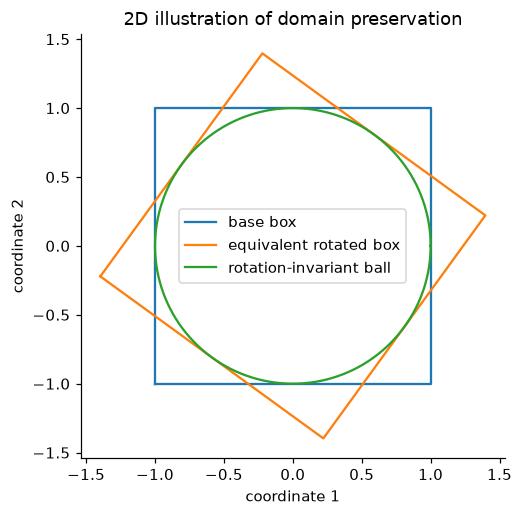

In [5]:
q=rotation(101)
ball=Domain("ball",q); box=Domain("box",q)
base=Domain("ball",np.eye(5)).sample(np.random.default_rng(0),5)
checks=[]
for u in base:
    z=ball.from_base(u)
    checks.append({"base_loss":battery(u),"mapped_loss":battery(ball.to_base(z)),
                   "roundtrip_error":np.max(np.abs(u-ball.to_base(z))),"feasible":ball.feasible(z)})
display(pd.DataFrame(checks))
assert np.allclose(q.T@q,np.eye(5),atol=1e-12)
assert all(np.isclose(r["base_loss"],r["mapped_loss"],atol=1e-14) for r in checks)
# A 2D illustration, not a projection of the five-dimensional battery feasible set.
angle=np.pi/5; q2=np.array([[np.cos(angle),-np.sin(angle)],[np.sin(angle),np.cos(angle)]])
square=np.array([[-1,-1],[-1,1],[1,1],[1,-1],[-1,-1]])
t=np.linspace(0,2*np.pi,300)
fig,ax=plt.subplots(figsize=(5,5))
rotated=square@q2
ax.plot(square[:,0],square[:,1],label="base box")
ax.plot(rotated[:,0],rotated[:,1],label="equivalent rotated box")
ax.plot(np.cos(t),np.sin(t),label="rotation-invariant ball")
ax.set_aspect("equal"); ax.legend(); ax.set(title="2D illustration of domain preservation",xlabel="coordinate 1",ylabel="coordinate 2")
save_figure(fig,"geometry_domains"); plt.show()

## Conditioning is measured separately from orientation

Compute $H_{GN}=2J^TJ/T$ at the reference fit, in dimensionless log coordinates. This is a **local Gauss–Newton approximation**, not an exact global Hessian. Very small eigenvalues can indicate weakly informed parameter combinations; branch permutations also create equivalent solutions.

An orthogonal rotation gives $Q^TH_{GN}Q$ and preserves its eigenvalues. Controlled changes of condition number therefore belong to the synthetic quadratic experiment, not to rotation itself. These derivative calculations are extra diagnostic simulator calls, unavailable to BO/CMA.

0    0.000168
1    0.000425
2    0.001239
3    0.009848
4    0.093152
Name: Local Gauss–Newton eigenvalues, dtype: float64

Diagnostic cost: {'extra_simulator_calls': 10, 'difference_step': 0.0001, 'interpretation': 'local Gauss-Newton approximation, not the exact global Hessian'}
Spectral ratio: 555.1124907847354


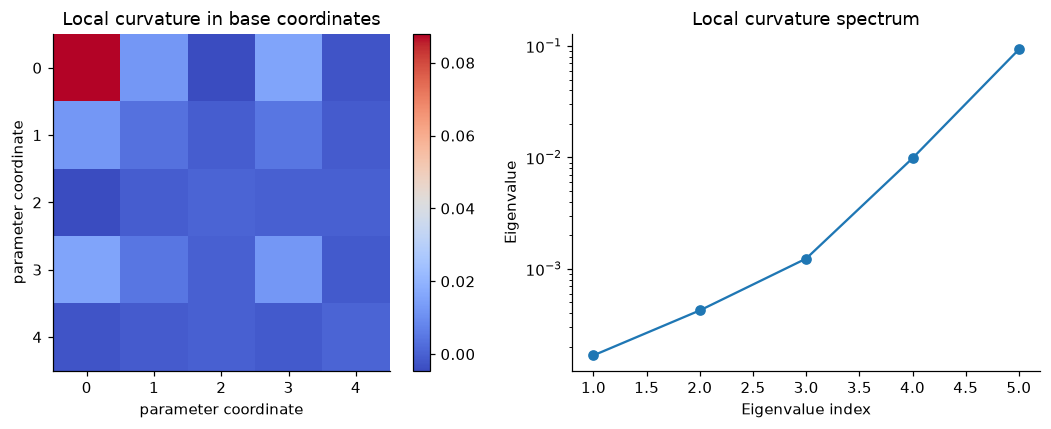

In [6]:
hessian,eigenvalues,diagnostic_cost=curvature(reference_two)
display(pd.Series(eigenvalues,name="Local Gauss–Newton eigenvalues"))
print("Diagnostic cost:",diagnostic_cost)
print("Spectral ratio:",eigenvalues[-1]/eigenvalues[0] if eigenvalues[0]>0 else "singular")
assert np.allclose(np.linalg.eigvalsh(q.T@hessian@q),eigenvalues,rtol=1e-7,atol=1e-12)
fig,axes=plt.subplots(1,2,figsize=(10,4))
image=axes[0].imshow(hessian,cmap="coolwarm"); fig.colorbar(image,ax=axes[0])
axes[0].set(title="Local curvature in base coordinates",xlabel="parameter coordinate",ylabel="parameter coordinate")
axes[1].semilogy(range(1,6),eigenvalues,"o-"); axes[1].set(title="Local curvature spectrum",xlabel="Eigenvalue index",ylabel="Eigenvalue")
fig.tight_layout(); save_figure(fig,"geometry_local_curvature"); plt.show()
pd.DataFrame({"eigenvalue":eigenvalues}).to_csv(ROOT/"results/tables/reference_local_curvature.csv",index=False)

## Interpretation boundary
A low voltage error does not establish that the fitted resistances and timescales are uniquely correct. Report proximity to parameter bounds, reference-fit termination, branch ambiguity, OCV transfer and residual structure alongside predictive error. The following pilot tests optimiser behaviour under this declared objective; it does not validate all battery physics.